# ECMWF IFS vs. AIFS 500mb Geopotential Height Comparison Across Europe

In this example we will use WxData to download the latest forecasts for 500mb Geopotential Height for ECMWF IFS and ECMWF AIFS.

```python
def ecmwf_ifs(final_forecast_hour=360,
              western_bound=-180,
              eastern_bound=180,
              northern_bound=90,
              southern_bound=-90,
              step=3,
              proxies=None,
              process_data=True,
              clear_recycle_bin=False,
              convert_temperature=True,
              convert_to='celsius',
              custom_directory=None,
              notifications='off',
              source='ecmwf',
              level_type='pressure',
              clear_data=False,
              variables=['geopotential height',
                        'specific humidity',
                        'relative humidity',
                        'temperature',
                        'u-wind component',
                        'v-wind component'],
              levels=[1000, 
                      925, 
                      850, 
                      700, 
                      600, 
                      500, 
                      400, 
                      300, 
                      250, 
                      200, 
                      150, 
                      100, 
                      50],
            to_netcdf=False,
            netcdf_path=f"ECMWF IFS/NETCDF",
            netcdf_filename=f"ecmwf_ifs.nc",
            delete_previous_netcdf_file=True,
            return_values=True):

def ecmwf_aifs(final_forecast_hour=360,
                    western_bound=-180,
                    eastern_bound=180,
                    northern_bound=90,
                    southern_bound=-90,
                    proxies=None,
                    process_data=True,
                    clear_recycle_bin=False,
                    convert_temperature=True,
                    convert_to='celsius',
                    custom_directory=None,
                    notifications='off',
                    source='ecmwf',
                    level_type='pressure',
                    clear_data=False,
                    variables=['geopotential height',
                                'specific humidity',
                                'relative humidity',
                                'temperature',
                                'u-wind component',
                                'v-wind component'],
                    levels=[1000, 
                            925, 
                            850, 
                            700, 
                            600, 
                            500, 
                            400, 
                            300, 
                            250, 
                            200, 
                            150, 
                            100, 
                            50],
                to_netcdf=False,
                netcdf_path=f"ECMWF AIFS/NETCDF",
                netcdf_filename=f"ecmwf_aifs.nc",
                delete_previous_netcdf_file=True,
                return_values=True):
```

[ECMWF IFS Client Documentation](https://edrewitz.github.io/WxData/ECMWF_IFS)

[ECMWF AIFS Client Documentation](https://edrewitz.github.io/WxData/ECMWF_AIFS)

## Imports

In [1]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import xarray as xr

from wxdata import ecmwf_ifs, ecmwf_aifs
from datetime import timedelta

In [2]:
# Let's download from our default server of ECMWF Open-Data
# Let's set the step=6 so it is consistent with AIFS

ifs = ecmwf_ifs(variables=['geopotential height'],
                levels=[500],
                western_bound=-30,
                eastern_bound=50,
                southern_bound=30,
                northern_bound=75,
                step=6)

20261029180000-0h-oper-fc.grib2:   0%|          | 0.00/394k [00:00<?, ?B/s]

20261029180000-6h-oper-fc.grib2:   0%|          | 0.00/392k [00:00<?, ?B/s]

20261029180000-12h-oper-fc.grib2:   0%|          | 0.00/390k [00:00<?, ?B/s]

20261029180000-18h-oper-fc.grib2:   0%|          | 0.00/391k [00:00<?, ?B/s]

20261029180000-24h-oper-fc.grib2:   0%|          | 0.00/391k [00:00<?, ?B/s]

...

20261029180000-126h-oper-fc.grib2:   0%|          | 0.00/375k [00:00<?, ?B/s]

20261029180000-132h-oper-fc.grib2:   0%|          | 0.00/374k [00:00<?, ?B/s]

20261029180000-138h-oper-fc.grib2:   0%|          | 0.00/373k [00:00<?, ?B/s]

20261029180000-144h-oper-fc.grib2:   0%|          | 0.00/373k [00:00<?, ?B/s]

ECMWF IFS Download Complete.
ECMWF IFS Data Processing...
ECMWF IFS Data Processing Complete.


In [3]:
# Let's download AIFS from Google Cloud
# Since the 18z IFS has 144 hours, let's set final_forecast_hour=144 for AIFS

aifs = ecmwf_aifs(final_forecast_hour=144,
                  variables=['geopotential height'],
                  levels=[500],
                  western_bound=-30,
                  eastern_bound=50,
                  southern_bound=30,
                  northern_bound=75,
                 source='google')

20261029180000-0h-oper-fc.grib2:   0%|          | 0.00/391k [00:00<?, ?B/s]

20261029180000-6h-oper-fc.grib2:   0%|          | 0.00/385k [00:00<?, ?B/s]

20261029180000-12h-oper-fc.grib2:   0%|          | 0.00/383k [00:00<?, ?B/s]

20261029180000-18h-oper-fc.grib2:   0%|          | 0.00/384k [00:00<?, ?B/s]

20261029180000-24h-oper-fc.grib2:   0%|          | 0.00/383k [00:00<?, ?B/s]

...

20261029180000-126h-oper-fc.grib2:   0%|          | 0.00/387k [00:00<?, ?B/s]

20261029180000-132h-oper-fc.grib2:   0%|          | 0.00/388k [00:00<?, ?B/s]

20261029180000-138h-oper-fc.grib2:   0%|          | 0.00/390k [00:00<?, ?B/s]

20261029180000-144h-oper-fc.grib2:   0%|          | 0.00/391k [00:00<?, ?B/s]

ECMWF AIFS Download Complete.
ECMWF AIFS Data Processing...
ECMWF AIFS Data Processing Complete.


In [4]:
ifs

<xarray.Dataset> Size: 6MB
Dimensions:              (step: 25, latitude: 181, longitude: 321)
Coordinates:
  * step                 (step) float64 200B 0.0 6.0 12.0 ... 132.0 138.0 144.0
  * latitude             (latitude) float64 1kB 75.0 74.75 74.5 ... 30.25 30.0
  * longitude            (longitude) float64 3kB -30.0 -29.75 ... 49.75 50.0
    time                 datetime64[ns] 8B 2026-10-29T18:00:00
    isobaricInhPa        float64 8B ...
    valid_time           datetime64[ns] 8B ...
Data variables:
    geopotential_height  (step, latitude, longitude) float32 6MB dask.array<chunksize=(1, 181, 321), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T18:47 GRIB to CDM+CF via cfgrib-0.9.1...

In [5]:
aifs

<xarray.Dataset> Size: 6MB
Dimensions:              (step: 25, latitude: 181, longitude: 321)
Coordinates:
  * step                 (step) float64 200B 0.0 6.0 12.0 ... 132.0 138.0 144.0
  * latitude             (latitude) float64 1kB 75.0 74.75 74.5 ... 30.25 30.0
  * longitude            (longitude) float64 3kB -30.0 -29.75 ... 49.75 50.0
    time                 datetime64[ns] 8B 2026-10-29T18:00:00
    isobaricInhPa        float64 8B ...
    valid_time           datetime64[ns] 8B ...
Data variables:
    geopotential_height  (step, latitude, longitude) float32 6MB dask.array<chunksize=(1, 181, 321), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T18:47 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
# Combine the two datasets from the ECMWF IFS & ECMWF AIFS

ds = xr.concat([ifs, aifs], dim="dataset")

In [7]:
ds

<xarray.Dataset> Size: 12MB
Dimensions:              (dataset: 2, step: 25, latitude: 181, longitude: 321)
Coordinates:
  * step                 (step) float64 200B 0.0 6.0 12.0 ... 132.0 138.0 144.0
  * latitude             (latitude) float64 1kB 75.0 74.75 74.5 ... 30.25 30.0
  * longitude            (longitude) float64 3kB -30.0 -29.75 ... 49.75 50.0
    time                 datetime64[ns] 8B 2026-10-29T18:00:00
    isobaricInhPa        float64 8B 500.0
    valid_time           datetime64[ns] 8B 2026-10-29T18:00:00
Dimensions without coordinates: dataset
Data variables:
    geopotential_height  (dataset, step, latitude, longitude) float32 12MB dask.array<chunksize=(1, 1, 181, 321), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T18:47 GRIB to CDM+CF via cfgrib-0.9.1...

In [8]:
# Find the ECMWF IFS + AIFS 500 MB Geopotential Height Forecast Mean

ds['mean_geopotential_height'] = (ds['geopotential_height'][0, :, :, :] + ds['geopotential_height'][1, :, :, :])/2

In [9]:
ds

<xarray.Dataset> Size: 17MB
Dimensions:                   (dataset: 2, step: 25, latitude: 181,
                               longitude: 321)
Coordinates:
  * step                      (step) float64 200B 0.0 6.0 12.0 ... 138.0 144.0
  * latitude                  (latitude) float64 1kB 75.0 74.75 ... 30.25 30.0
  * longitude                 (longitude) float64 3kB -30.0 -29.75 ... 50.0
    time                      datetime64[ns] 8B 2026-10-29T18:00:00
    isobaricInhPa             float64 8B 500.0
    valid_time                datetime64[ns] 8B 2026-10-29T18:00:00
Dimensions without coordinates: dataset
Data variables:
    geopotential_height       (dataset, step, latitude, longitude) float32 12MB dask.array<chunksize=(1, 1, 181, 321), meta=np.ndarray>
    mean_geopotential_height  (step, latitude, longitude) float32 6MB dask.array<chunksize=(1, 181, 321), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T18:47 GRIB to CDM+CF via cfgrib-0.9.1...

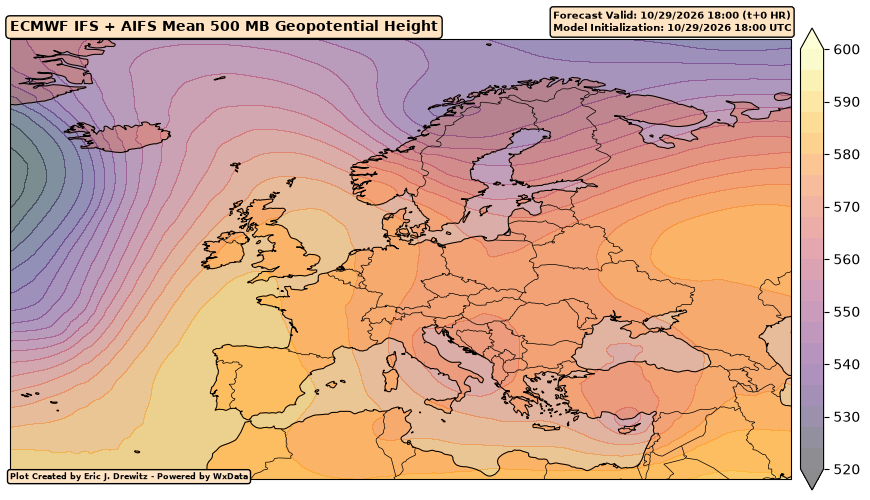

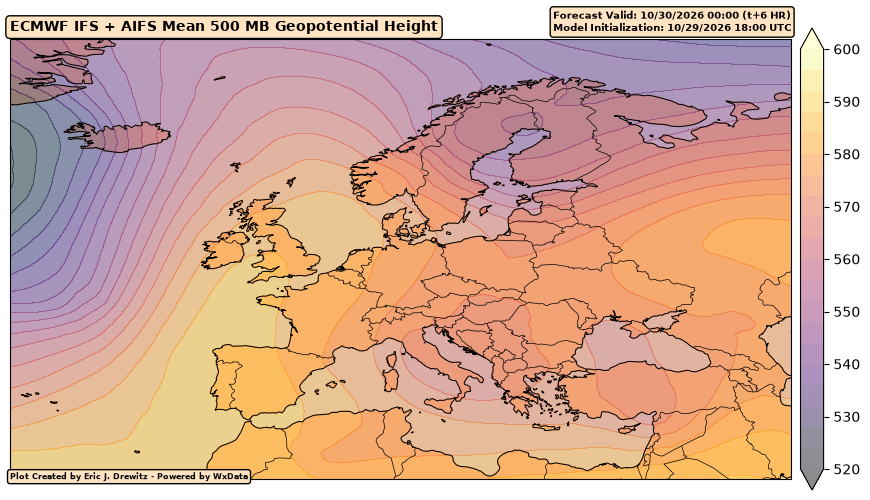

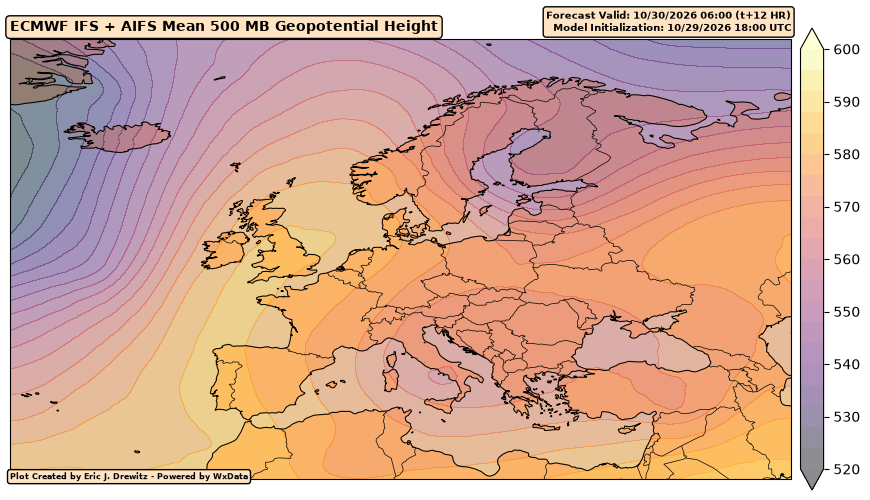

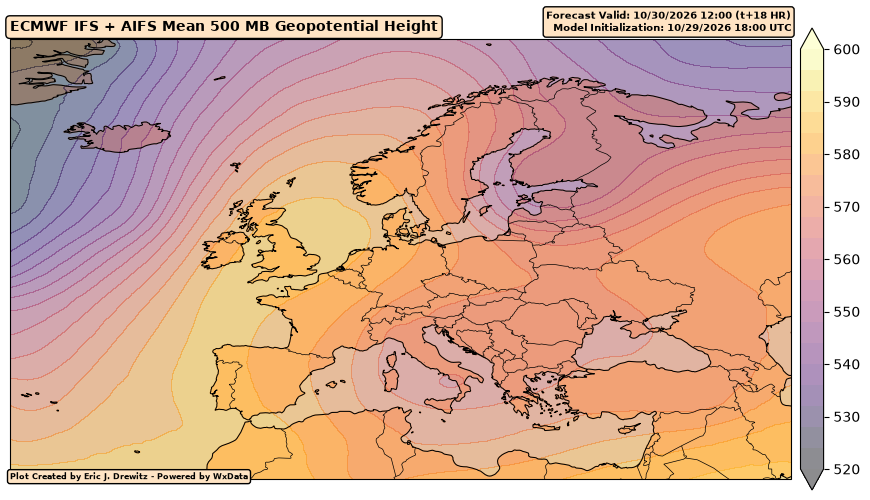

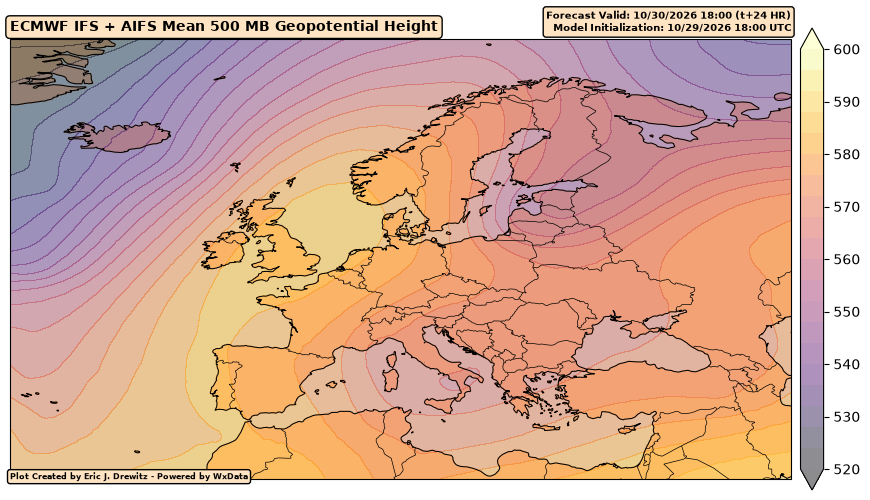

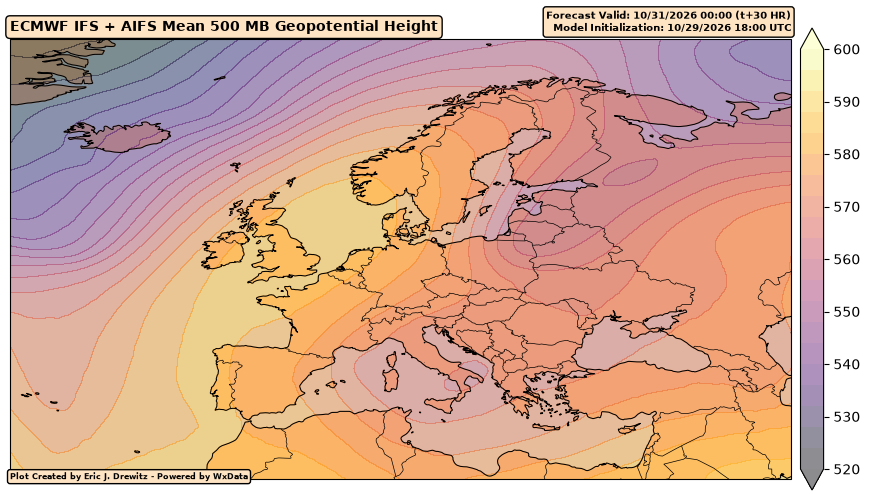

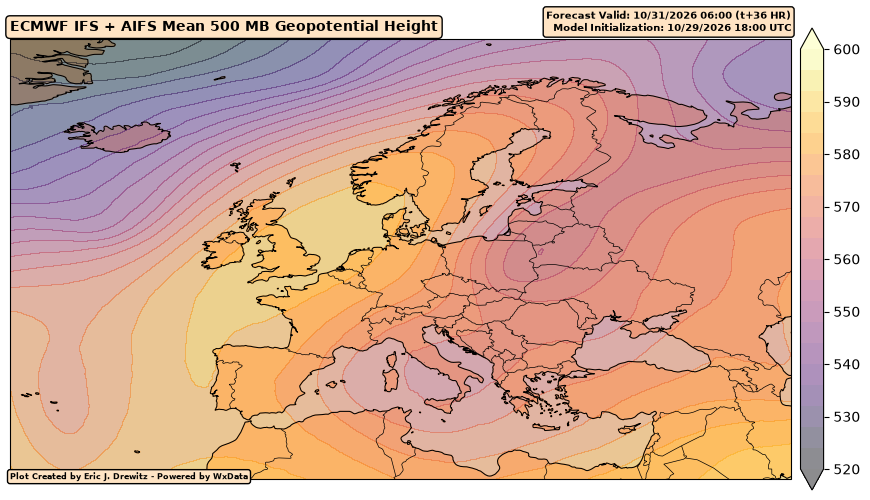

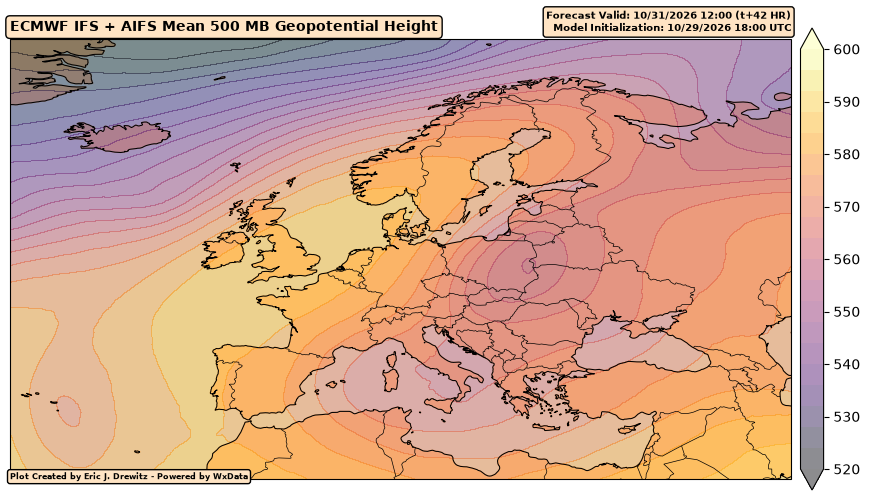

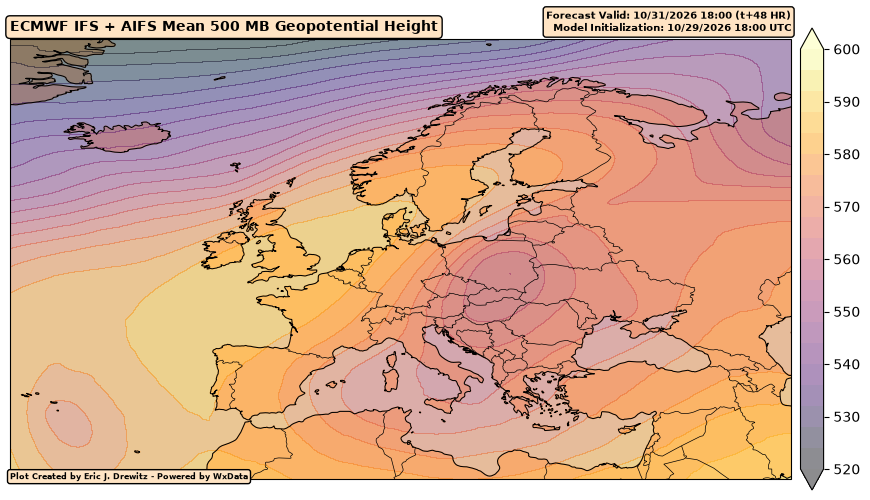

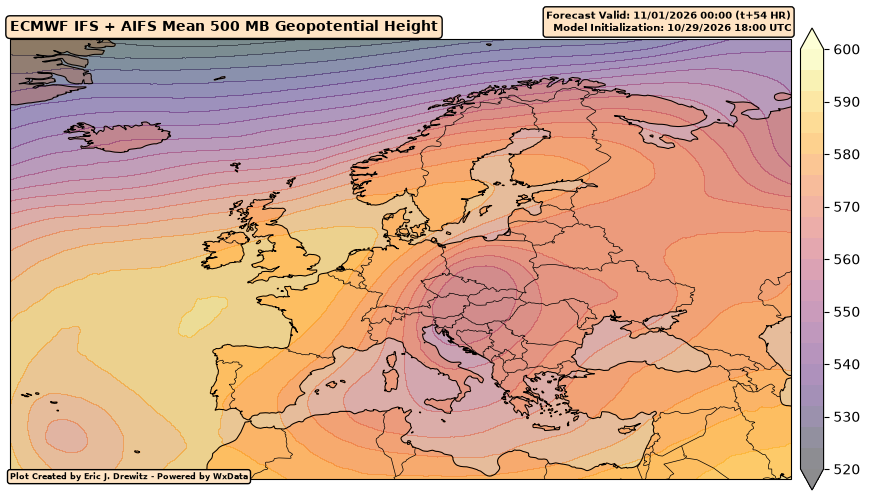

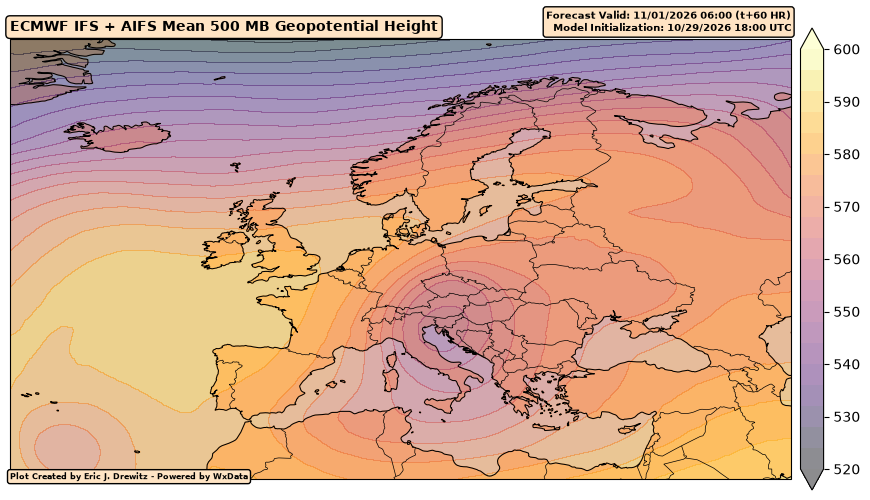

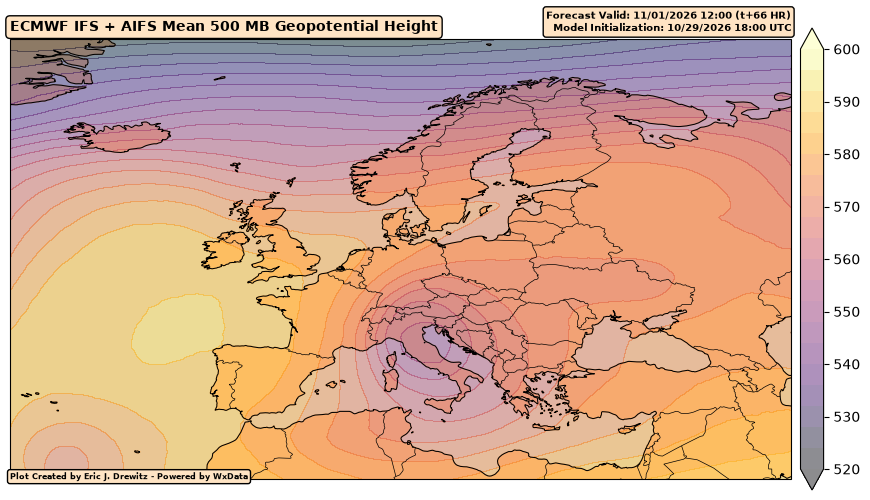

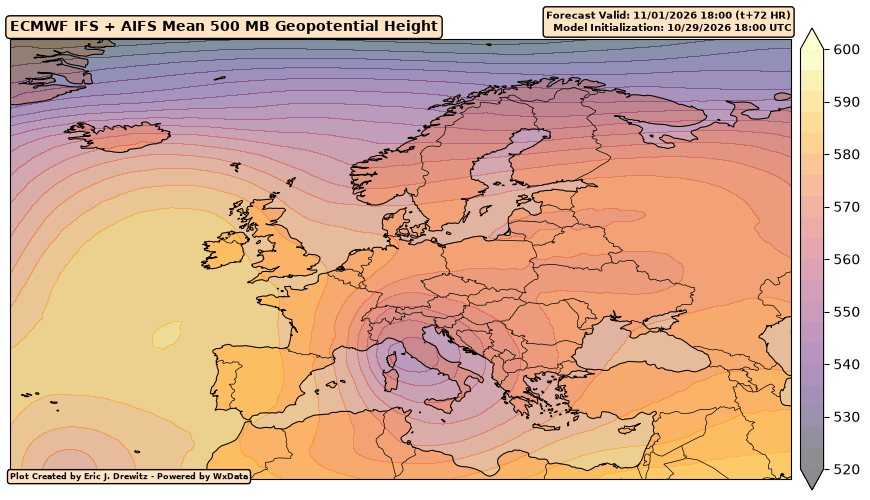

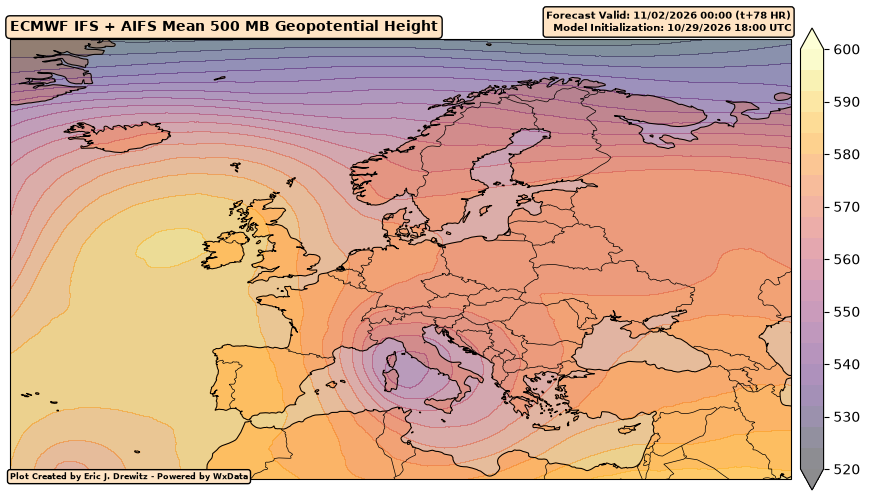

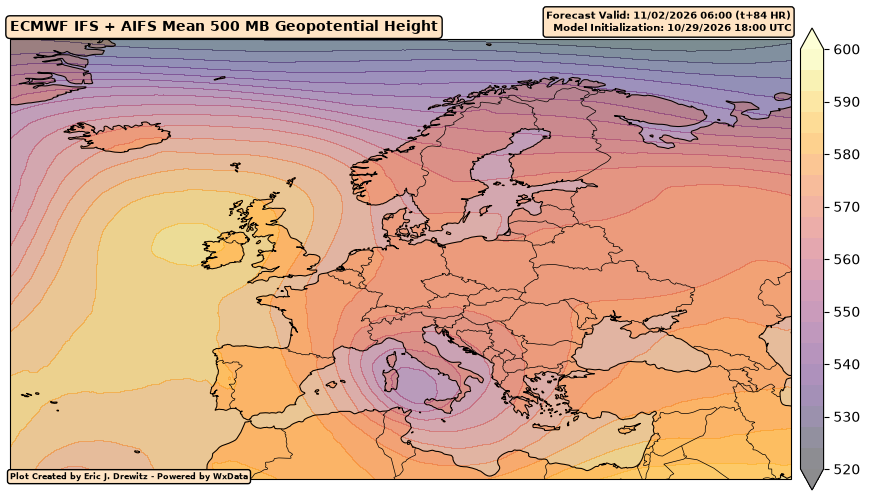

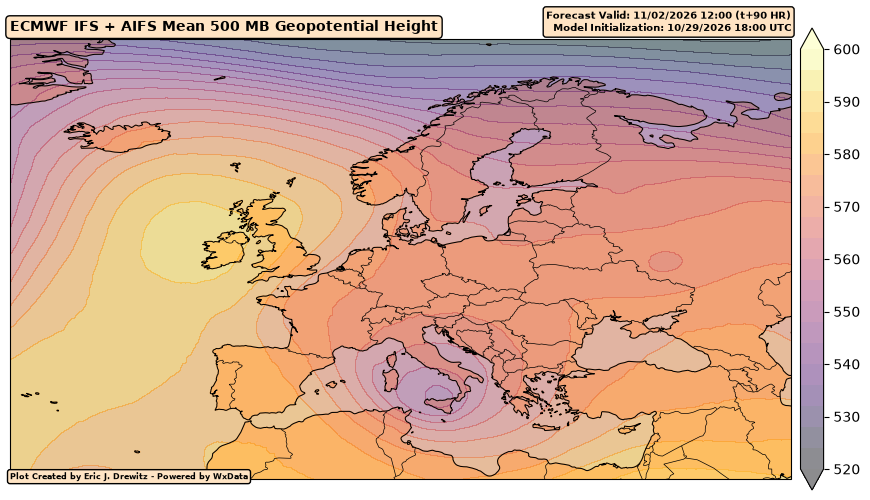

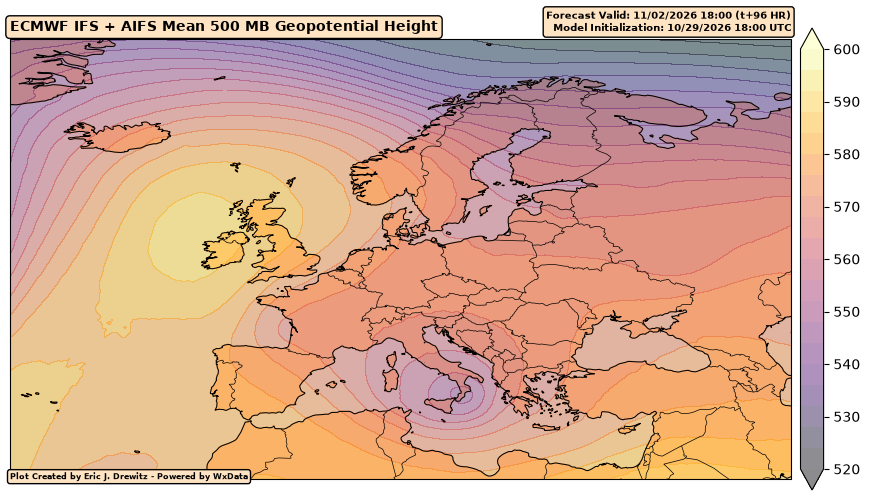

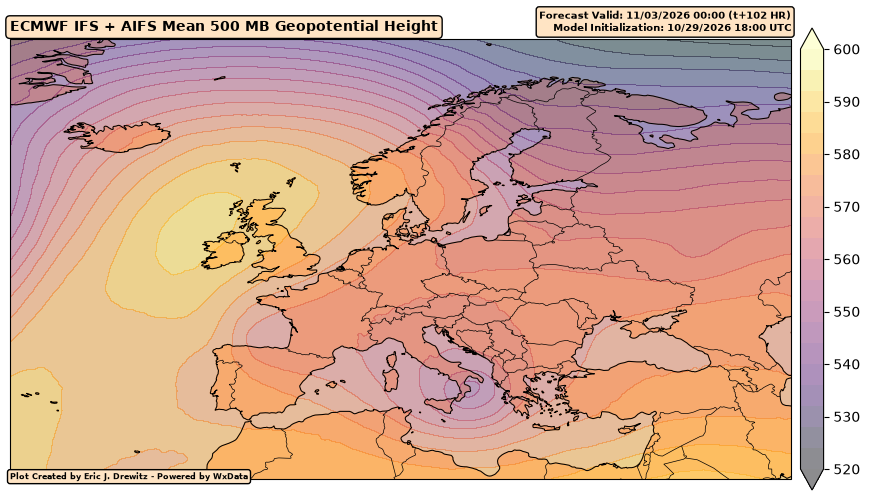

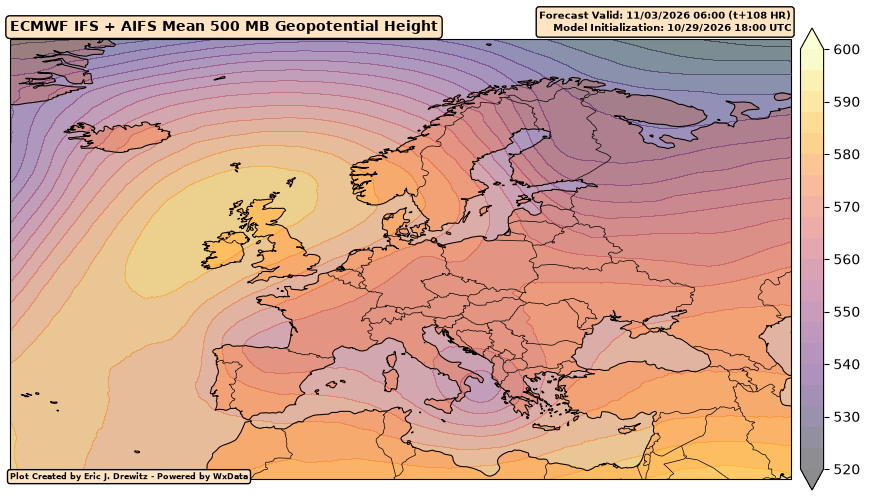

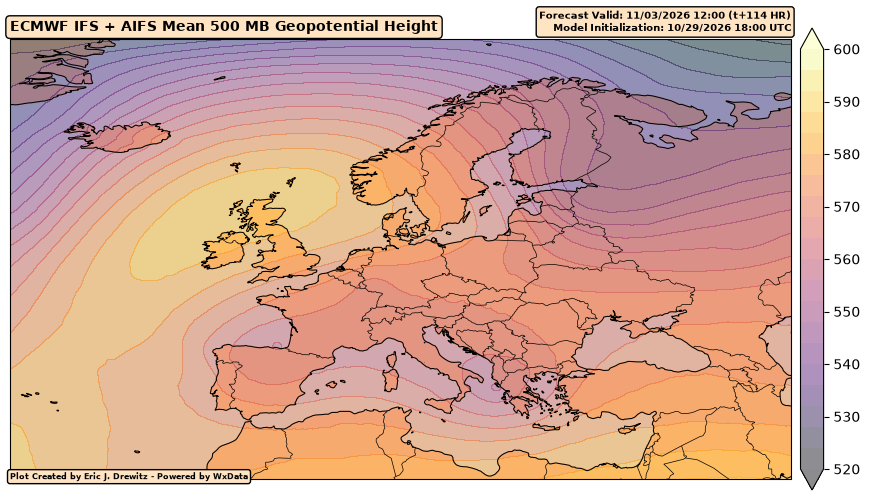

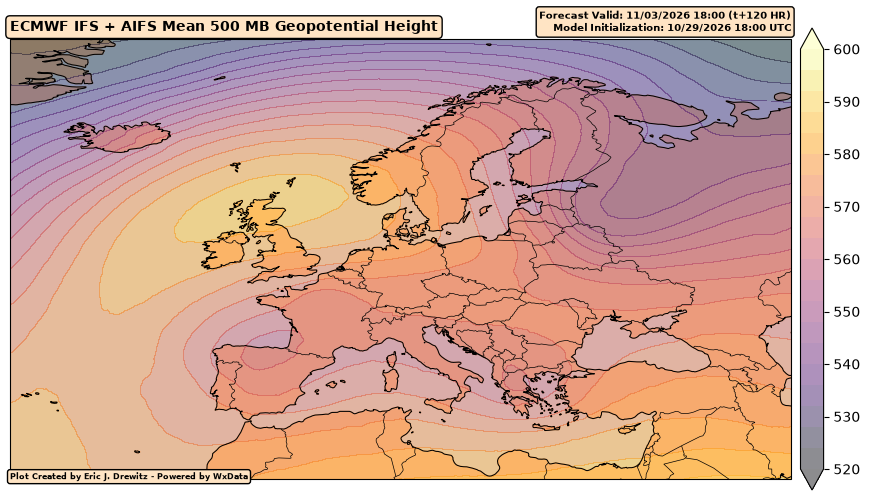

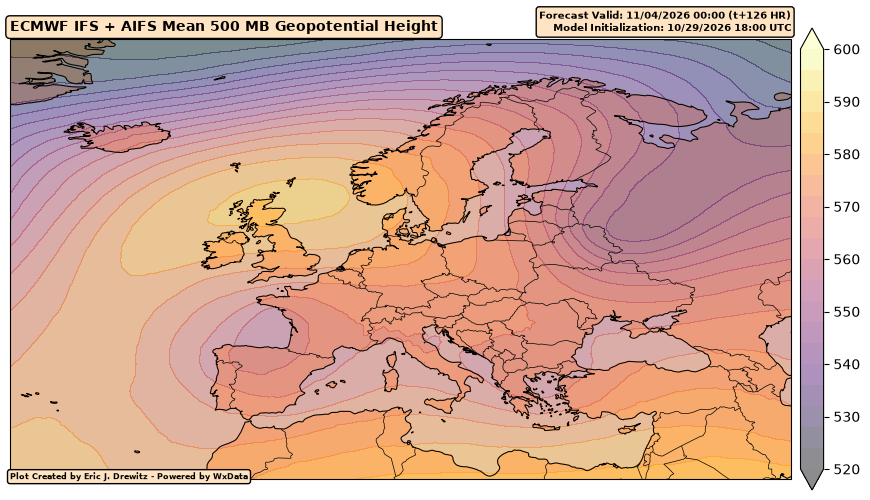

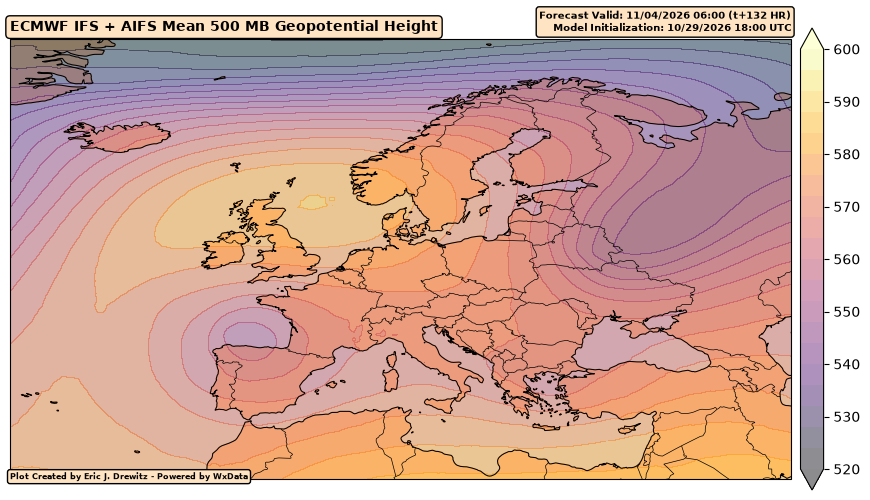

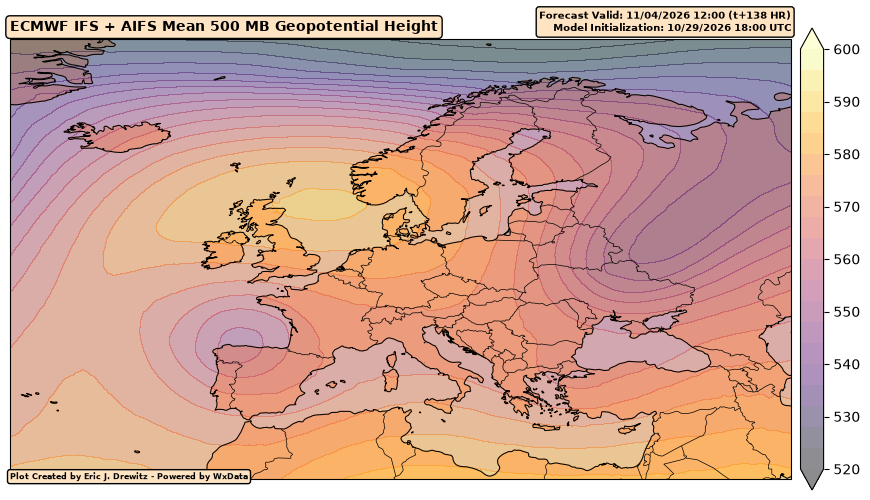

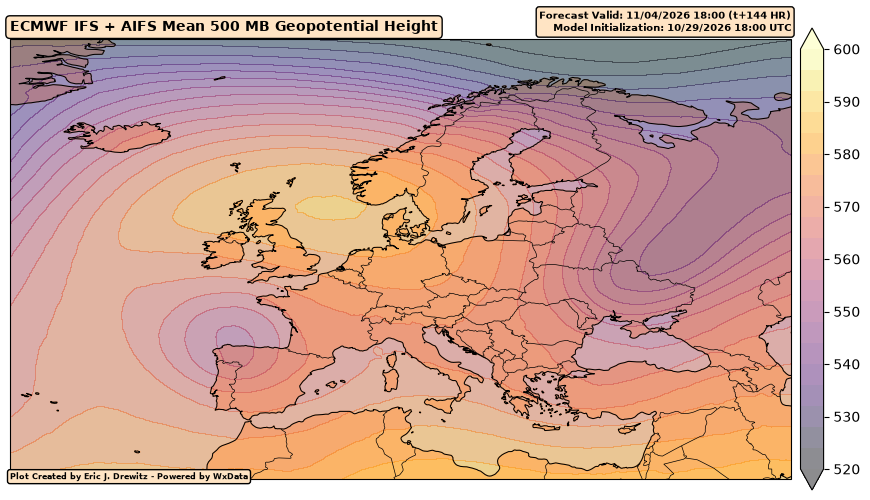

In [10]:
# Create our figure
for i in range(0, len(ds['step']), 1):
    fig = plt.figure(figsize=(12,12))
    
    # Create our subplot with a PlateCarree (lat/lon) projection
    ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())
    
    # Set our boundaries in a latlon format of [western_bound, eastern_bound, southern_bound, northern_bound] followed by our PlateCarree projection
    ax.set_extent([-30, 50, 30, 75], ccrs.PlateCarree())
    
    # Add our features to the map 
    # Add our coastlines
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.75, zorder=3)
    
    # Add the oceans, land, states, lakes and Canadian provinces and color them light cyan
    ax.add_feature(cfeature.OCEAN, color='lightcyan', zorder=1)
    ax.add_feature(cfeature.LAKES, color='lightcyan', zorder=1)
    ax.add_feature(cfeature.LAND, color='navajowhite', zorder=1)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=0.5, zorder=5)
    
    # Add our filled contours for temperature
    cs = ax.contourf(ds['longitude'], 
                   ds['latitude'], 
                   (ds['mean_geopotential_height'][i, :, :])/10, 
                   levels=np.arange(520, 604, 4), 
                   transform=ccrs.PlateCarree(),
                   alpha=0.45,
                   cmap='inferno',
                   extend='both')
    
    # Create our colorbar for our filled contours
    fig.colorbar(cs, 
                 shrink=0.5, 
                 pad=0.01,
                 ticks=np.arange(520, 610, 10))
    # Plot title
    plt.title(f"ECMWF IFS + AIFS Mean 500 MB Geopotential Height", 
                   fontsize=10, 
                   fontweight='bold',
                   bbox=dict(boxstyle='round', 
                                facecolor='bisque'),
                   loc='left')
    
    # Extract our valid time as a datetime object
    valid_time = pd.to_datetime(ifs['valid_time'].values)
    
    # Gets our new forecast hour (eventhough we are plotting the initial frame)
    times = ifs['step'].values
    forecast_time = valid_time + timedelta(hours=int(times[i]))
    
    # Secondary title for our model runtime
    plt.title(f"Forecast Valid: {forecast_time.strftime('%m/%d/%Y %H:00')} (t+{int(times[i])} HR)\nModel Initialization: {valid_time.strftime('%m/%d/%Y %H:00')} UTC", 
                    fontsize=7, 
                    fontweight='bold',
                    bbox=dict(boxstyle='round', 
                                facecolor='bisque'),
                    loc='right')
    
    # Adding my signature on the plot
    ax.text(0, 
            -0.001, 
            f"Plot Created by Eric J. Drewitz - Powered by WxData", 
            transform=ax.transAxes, 
            fontsize=6, 
            fontweight='bold', 
            bbox=dict(boxstyle='round', 
                    facecolor='bisque'),
           zorder=10)

    plt.show()